# Clustering

## Load Data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score

X = pd.read_csv('data/cleaned/clustering/features_scaled.csv')

print("Shape:", X.shape)
print("Missing values:", X.isnull().sum().sum())
print("String columns:", X.select_dtypes(include=["object", "string"]).columns)

Shape: (36452, 93)
Missing values: 0
String columns: Index([], dtype='str')


## PCA

In [2]:
pca = PCA(n_components=30, random_state=42)

X_pca = pca.fit_transform(X)

print("PCA shape:", X_pca.shape)
print("Explained variance:", pca.explained_variance_ratio_.sum())

PCA shape: (36452, 30)
Explained variance: 0.9128908137835154


## K-Means Clustering

In [3]:
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

k_values = range(2, 11)

sil_scores = []
db_scores = []
ch_scores = []
sse_scores = []

for k in k_values:

    kmeans = KMeans(
        n_clusters=k,
        n_init=50,
        random_state=42
    )

    clusters = kmeans.fit_predict(X_pca)

    sil = silhouette_score(X_pca, clusters)

    db = davies_bouldin_score(X_pca, clusters)

    ch = calinski_harabasz_score(X_pca, clusters)

    sil_scores.append(sil)
    db_scores.append(db)
    ch_scores.append(ch)

    # ELBOW METHOD (SSE / inertia)
    sse_scores.append(kmeans.inertia_)

    print(f"K = {k}")
    print("Silhouette:", sil)
    print("Davies-Bouldin:", db)
    print("Calinski-Harabasz:", ch)
    print("SSE:", kmeans.inertia_)
    print()

K = 2
Silhouette: 0.15822690158833166
Davies-Bouldin: 2.1751137237487383
Calinski-Harabasz: 6978.714928422129
SSE: 474260.4652654233

K = 3
Silhouette: 0.1446045424705556
Davies-Bouldin: 2.305092140787366
Calinski-Harabasz: 5508.280923219652
SSE: 433913.7734916005

K = 4
Silhouette: 0.1446777768743519
Davies-Bouldin: 1.7875030610191334
Calinski-Harabasz: 4714.55241392694
SSE: 407090.7729044574

K = 5
Silhouette: 0.14074098890616302
Davies-Bouldin: 1.7898245558570438
Calinski-Harabasz: 4400.891589999399
SSE: 381029.0289512587

K = 6
Silhouette: 0.1394258236063821
Davies-Bouldin: 1.7641875928233803
Calinski-Harabasz: 4129.124691905411
SSE: 360723.2445668045

K = 7
Silhouette: 0.12900423519417417
Davies-Bouldin: 1.8185567879407425
Calinski-Harabasz: 3850.522190254867
SSE: 345832.79761081754

K = 8
Silhouette: 0.11526109951951813
Davies-Bouldin: 1.9735459772805821
Calinski-Harabasz: 3598.2627092558096
SSE: 334131.4108930797

K = 9
Silhouette: 0.12042323271941525
Davies-Bouldin: 1.970021665

## Results

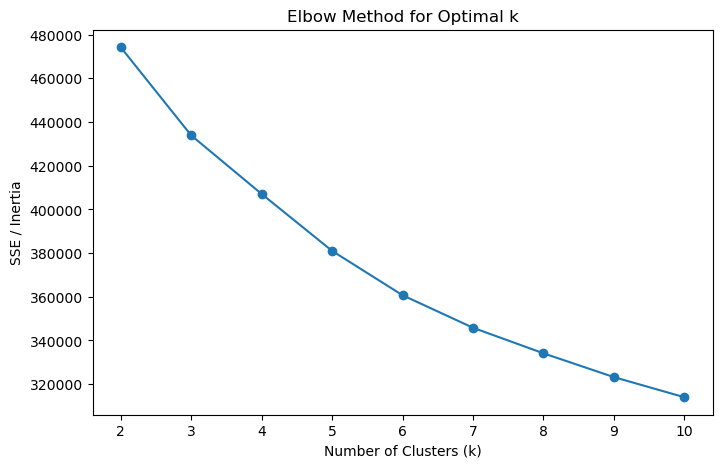

In [4]:
plt.figure(figsize=(8,5))

plt.plot(
    k_values,
    sse_scores,
    marker='o'
)

plt.xlabel("Number of Clusters (k)")
plt.ylabel("SSE / Inertia")
plt.title("Elbow Method for Optimal k")

plt.show()

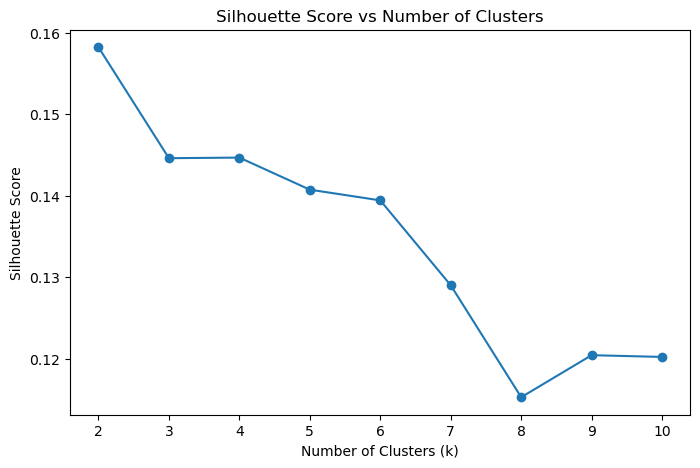

In [5]:
plt.figure(figsize=(8,5))

plt.plot(k_values, sil_scores, marker='o')

plt.xlabel("Number of Clusters (k)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score vs Number of Clusters")

plt.show()

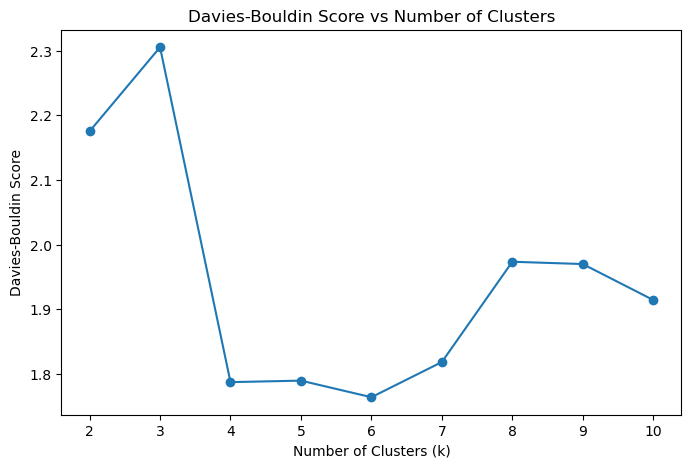

In [6]:
plt.figure(figsize=(8,5))

plt.plot(k_values, db_scores, marker='o')

plt.xlabel("Number of Clusters (k)")
plt.ylabel("Davies-Bouldin Score")
plt.title("Davies-Bouldin Score vs Number of Clusters")

plt.show()

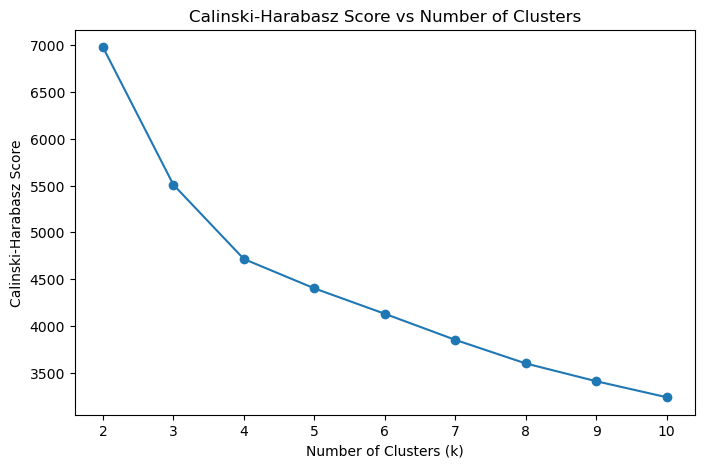

In [7]:
plt.figure(figsize=(8,5))

plt.plot(k_values, ch_scores, marker='o')

plt.xlabel("Number of Clusters (k)")
plt.ylabel("Calinski-Harabasz Score")
plt.title("Calinski-Harabasz Score vs Number of Clusters")

plt.show()

The clustering metrics suggested that k=2 was the strongest overall choice because it produced the highest Silhouette and Calinski-Harabasz scores. Although the Davies-Bouldin score slightly favored a larger k value, larger k values created smaller and less balanced clusters, making k=2 the most stable and interpretable clustering solution.

## Best K-Means Summary

In [8]:
best_k = 2

kmeans = KMeans(
    n_clusters=best_k,
    n_init=50,
    random_state=42
)

clusters = kmeans.fit_predict(X_pca)

print(pd.Series(clusters).value_counts().sort_index())

0    19151
1    17301
Name: count, dtype: int64


In [9]:
clustered_df = X.copy()
clustered_df["cluster"] = clusters

cluster_summary = clustered_df.groupby("cluster").mean()

print(cluster_summary.T)

cluster_diff = cluster_summary.loc[1] - cluster_summary.loc[0]

top_positive = cluster_diff.sort_values(ascending=False).head(15)
top_negative = cluster_diff.sort_values(ascending=True).head(15)

print("Features higher in Cluster 1:")
print(top_positive)

print("\nFeatures higher in Cluster 0:")
print(top_negative)

cluster                        0         1
skills_count           -0.026751  0.029611
revenue_rank            0.017555 -0.019432
employee_rank           0.062341 -0.069007
company_score          -0.018774  0.020782
reviews_count           0.015149 -0.016768
...                          ...       ...
skill_machine_learning  0.018224  0.038495
skill_hadoop            0.017336  0.030403
skill_html              0.028197  0.018091
skill_phd               0.017754  0.028553
skill_cma               0.013629  0.030114

[93 rows x 2 columns]
Features higher in Cluster 1:
bls_annual_mean                  1.471179
bls_annual_median                1.420683
bls_p90                          1.334393
bls_p10                          1.318039
pce_2023_in_millions             0.958225
total_employed                   0.936154
occ_title_Financial Managers     0.403487
jobs_group_Controller            0.268242
skill_cpa                        0.157189
jobs_group_CFO                   0.135244
occ_title_D

Cluster interpretation was performed by comparing the mean feature values of Cluster 1 and Cluster 0. Cluster 1 was associated with higher BLS wage statistics, total employment, PCE, and financial-management-related features, while Cluster 0 was relatively lower on these wage and economic indicators. This suggests that the final KMeans model separated the data into two broad groups based on compensation, economic context, occupation type, and skill patterns.

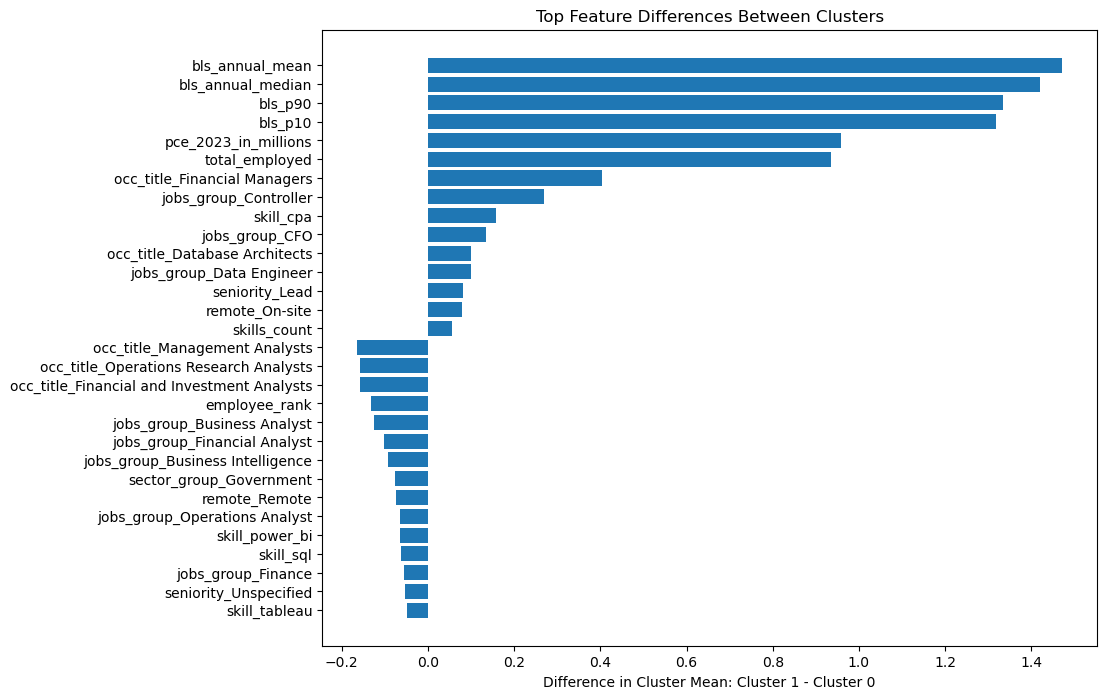

In [10]:
top_differences = pd.concat([
    top_positive,
    top_negative
])

plt.figure(figsize=(10, 8))

plt.barh(
    top_differences.index,
    top_differences.values
)

plt.xlabel("Difference in Cluster Mean: Cluster 1 - Cluster 0")
plt.title("Top Feature Differences Between Clusters")

plt.gca().invert_yaxis()

plt.show()

The feature difference graph highlights the variables that most strongly distinguish the two clusters. Positive values indicate features that are more associated with Cluster 1, while negative values indicate features that are more associated with Cluster 0. This helps make the clustering results more interpretable by showing which job, wage, and skill-related features contributed most to the separation.

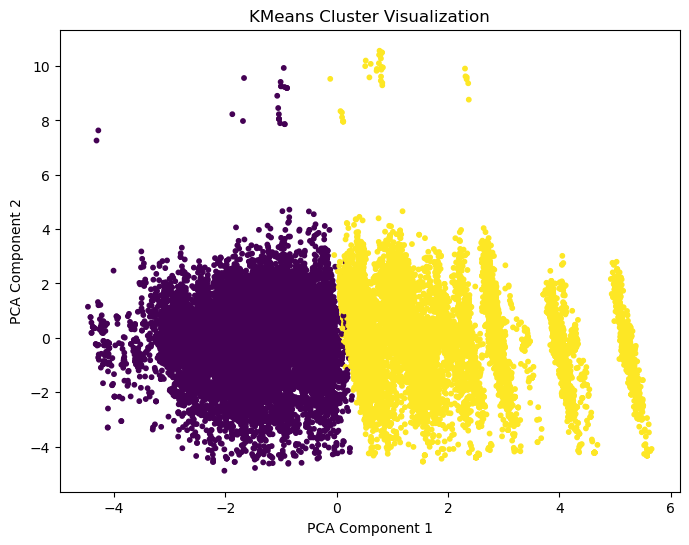

In [11]:
pca_2d = PCA(
    n_components=2,
    random_state=42
)

X_2d = pca_2d.fit_transform(X)

plt.figure(figsize=(8,6))

plt.scatter(
    X_2d[:,0],
    X_2d[:,1],
    c=clusters,
    s=10
)

plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.title("KMeans Cluster Visualization")

plt.show()

The 2D PCA visualization shows the final KMeans clustering result projected onto the first two principal components. The clusters show broad separation, although some overlap is expected because the original dataset contains high-dimensional real-world job and salary features. The visualization supports the idea that the data contains two major groupings rather than many clearly separated small clusters.

## PCA vs. Non-PCA

In [12]:
best_k = 2

kmeans_raw = KMeans(
    n_clusters=best_k,
    n_init=50,
    random_state=42
)

raw_clusters = kmeans_raw.fit_predict(X)

raw_sil = silhouette_score(X, raw_clusters)
raw_db = davies_bouldin_score(X, raw_clusters)
raw_ch = calinski_harabasz_score(X, raw_clusters)

kmeans_pca = KMeans(
    n_clusters=best_k,
    n_init=50,
    random_state=42
)

pca_clusters = kmeans_pca.fit_predict(X_pca)

pca_sil = silhouette_score(X_pca, pca_clusters)
pca_db = davies_bouldin_score(X_pca, pca_clusters)
pca_ch = calinski_harabasz_score(X_pca, pca_clusters)

comparison_df = pd.DataFrame({
    "Method": ["No PCA", "PCA"],
    "Silhouette": [raw_sil, pca_sil],
    "Davies-Bouldin": [raw_db, pca_db],
    "Calinski-Harabasz": [raw_ch, pca_ch]
})

print(comparison_df)

   Method  Silhouette  Davies-Bouldin  Calinski-Harabasz
0  No PCA    0.144159        2.309104        6269.521737
1     PCA    0.158227        2.175114        6978.714928


The PCA vs No PCA comparison shows that PCA improved all three clustering metrics for k=2. The PCA version had a higher Silhouette score, lower Davies-Bouldin score, and higher Calinski-Harabasz score than clustering on the original scaled feature space. This supports using PCA before KMeans because it reduced noise and redundancy while preserving most of the dataset variance.

## DBSCAN

In [13]:
from sklearn.cluster import DBSCAN

dbscan = DBSCAN(
    eps=3,
    min_samples=10
)

dbscan_clusters = dbscan.fit_predict(X_pca)

print(pd.Series(dbscan_clusters).value_counts().sort_index())

-1      116
 0    36248
 1       11
 2       49
 3       28
Name: count, dtype: int64


In [14]:
non_noise_mask = dbscan_clusters != -1
non_noise_clusters = dbscan_clusters[non_noise_mask]

if len(set(non_noise_clusters)) >= 2:
    db_sil = silhouette_score(X_pca[non_noise_mask], non_noise_clusters)
    db_db = davies_bouldin_score(X_pca[non_noise_mask], non_noise_clusters)
    db_ch = calinski_harabasz_score(X_pca[non_noise_mask], non_noise_clusters)

    print("DBSCAN Silhouette:", db_sil)
    print("DBSCAN Davies-Bouldin:", db_db)
    print("DBSCAN Calinski-Harabasz:", db_ch)
else:
    print("DBSCAN did not find enough non-noise clusters for metric evaluation.")

DBSCAN Silhouette: 0.42500406603546287
DBSCAN Davies-Bouldin: 0.8023073388757331
DBSCAN Calinski-Harabasz: 493.7267806246206


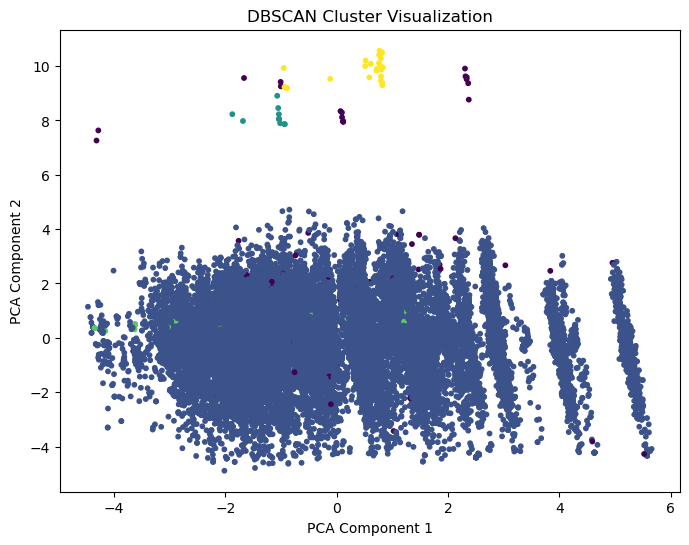

In [15]:
plt.figure(figsize=(8,6))

plt.scatter(
    X_2d[:, 0],
    X_2d[:, 1],
    c=dbscan_clusters,
    s=10
)

plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.title("DBSCAN Cluster Visualization")

plt.show()

DBSCAN produced one very large cluster and several very small clusters/noise groups. Although its Silhouette and Davies-Bouldin scores appear strong, the cluster-size distribution suggests that DBSCAN mainly identified a few dense outlier groups rather than a balanced segmentation of the dataset. For this reason, KMeans with k=2 was kept as the main clustering model.

## Conclusion

Overall, this project applied PCA dimensionality reduction and multiple clustering techniques to identify structure within the engineered salary and job feature dataset. KMeans clustering with k=2 produced the most balanced and interpretable clustering solution based on Silhouette, Calinski-Harabasz, Davies-Bouldin, and SSE evaluation metrics. PCA improved clustering quality compared to clustering directly on the original feature space, while DBSCAN primarily identified a small number of dense outlier groups. Cluster interpretation analysis suggested that the final clusters were separated by differences in wage statistics, employment levels, economic indicators, occupation categories, and skill patterns.